DONE BY: THE LEARNING MACHINES                                                                                                                  ☾

# Prediction of LLM generating synthetic medical records

## Description

The target variable contains four anonymized classes:
- Model_A
- Model_B
- Model_C
- Model_D

These correspond to four different LLMs used to generate the data.

We have to use Logistic Regression with no penalty. 

imports:

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42


In [32]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="'penalty' was deprecated in version 1.8",
    category=FutureWarning
)

## Loading and inspecting the data

In [33]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

X_raw = train.drop(columns=["id","label","discharge_destination"])
y = train["label"]
X_test_raw = test.drop(columns=["id","discharge_destination"])

print("Train:", train.shape)
print("Test:", test.shape)
print("Classes:", sorted(y.unique()))

display(train.head())
display(train.isna().sum().sort_values(ascending=False).head(10))


Train: (2400, 26)
Test: (1600, 25)
Classes: ['Model_A', 'Model_B', 'Model_C', 'Model_D']


,id,age,sex,bmi,smoking_status,encounter_type,systolic_bp,diastolic_bp,heart_rate,respiratory_rate,...,diabetes,hypertension,chronic_kidney_disease,primary_diagnosis,num_medications,prior_visits_12m,length_of_stay_days,discharge_destination,readmitted_30d,label
0,5be091fe7010722968d37fbbbfa5adec,38,Male,30.4,Current,Urgent,160,95,105,28,...,No,No,No,Respiratory,6,10,3.0,Home,No,Model_B
1,7ebc8ab8f1dfede1237163cb2e71325f,48,Female,28.5,Current,Elective,128,76,78,16,...,No,No,No,Gastrointestinal,3,2,2.0,Home,No,Model_D
2,69f51e35fec3bda1d81f2cbf9ac8b827,53,Female,25.4,Never,Elective,130,78,77,19,...,No,No,No,Renal,1,1,3.0,Rehabilitation,No,Model_A
3,8c64aa346b72cad6cb179f254abfd71d,45,Male,28.2,Never,Elective,145,95,72,18,...,Yes,No,No,Cardiovascular,4,0,4.0,Home,No,Model_C
4,c8255d88bcfc566c5616bed411b55bd7,41,Male,27.9,Current,Emergency,150,94,115,22,...,No,No,No,Gastrointestinal,2,5,3.0,HomeHealth,No,Model_B


creatinine_mg_dl         572
glucose_mg_dl            536
sodium_mmol_l            500
hemoglobin_g_dl          500
bmi                      268
readmitted_30d             0
discharge_destination      0
length_of_stay_days        0
prior_visits_12m           0
num_medications            0
dtype: int64

We can make the following separation:

**categorical**
- binary:
  - sex
  - diabetes
  - hypertension
  - chronic_kidney_disease
  - readmitted_30d
- others:
  - id
  - primary_diagnosis
  - discharge_destination
  - smoking status
  - encounter_type
  - label ( target variable )

**numerical**
- quantitative:
  - age (int64)
  - systolic_bp (int64)
  - diastolic_bp (int64)
  - heart_rate (int64)
  - respiratory_rate (int64)
  - spo2 (int64)
  - num_medications (int64)
  - prior_visits_12m (int64)
- continuous:
  - bmi (float64)
  - temperature_c (float64)
  - glucose_mg_dl (float64)
  - creatinine_mg_dl (float64)
  - sodium_mmol_l (float64)
  - hemoglobin_g_dl (float64)
  - length_of_stay_days (float64)


The analysis of these categories was not done in this notebook, but for understanding concerns on how we chose the variables in feature encoding we are going to paste here the most important graphics (correlation between numerical variables ans correlation with the 4 models)

In [34]:
train_bp = train.copy()

num_features = [
    'age', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate', 
    'respiratory_rate', 'temperature_c', 'glucose_mg_dl', 'spo2',
    'creatinine_mg_dl', 'hemoglobin_g_dl', 'sodium_mmol_l',
    'num_medications', 'prior_visits_12m', 'length_of_stay_days'
]

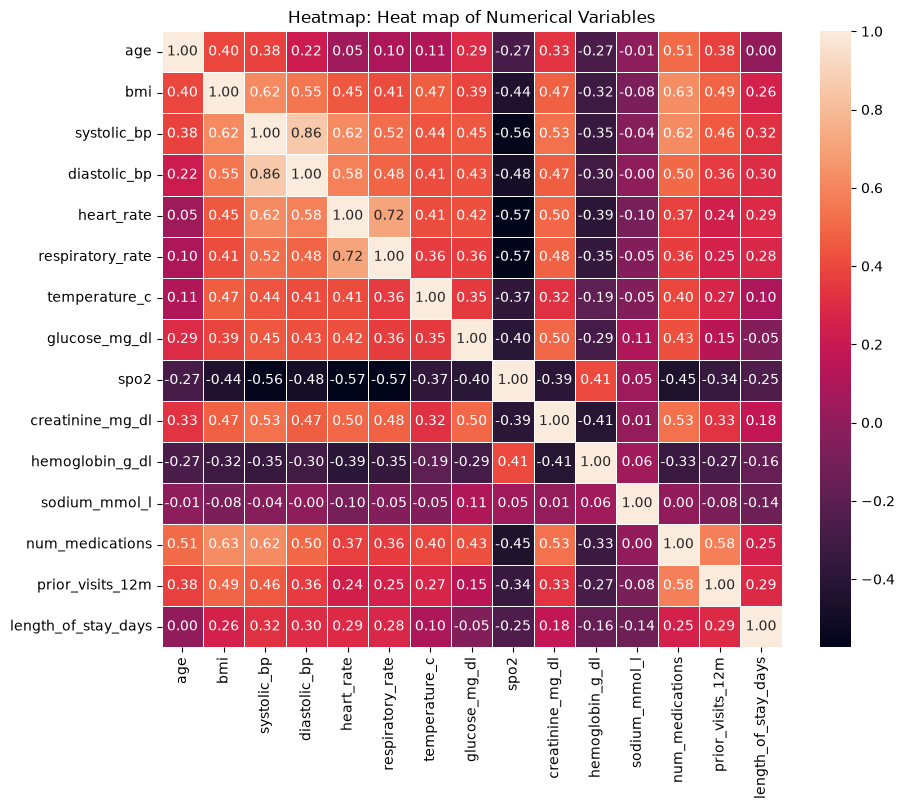

In [35]:
plt.figure(figsize=(10, 8))
correlation_matrix = train_bp[num_features].corr()
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    #cmap="Greens", 
    fmt=".2f", 
    linewidths=0.4
)
plt.title("Heatmap: Heat map of Numerical Variables")
plt.show()

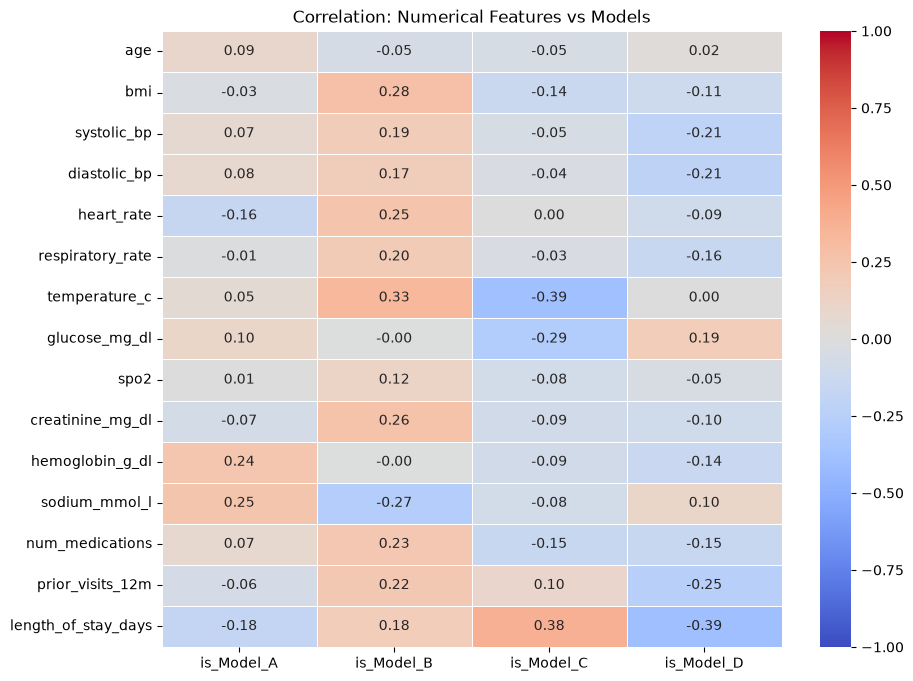

In [36]:
y_encoded = pd.get_dummies(train["label"], prefix="is")

correlation_matrix = pd.concat(
    [train_bp[num_features], y_encoded],
    axis=1
).corr()

# mostrar només correlacions entre features numèriques i output
correlation_matrix = correlation_matrix.loc[
    num_features, y_encoded.columns
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.4,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation: Numerical Features vs Models")
plt.show()


## Feature engineering

We create some new features with medical combinations like mean arterial pressure or BMI and age interaction.

We also create last digit (_ld) and exact value (_ex) features. For example, for bmi we then have:
- 'bmi': allows to learn a continuous relationship, like if high values of BMI favour a certain class.
- 'bmi_ex' : the exact value with 2 decimals in string form. Allows to learn if for example the value "30.4" is specially frequent in a class.
-  'bmi_ld' : the last digit of the number. Allows to learn if for example the last decimal "4" is a fingerprint of the generating model.

In [37]:
BINARY_COLUMNS = ["diabetes", "hypertension", "chronic_kidney_disease", "readmitted_30d"]
INTEGER_COLUMNS = ["age", "systolic_bp", "diastolic_bp", "heart_rate", "glucose_mg_dl", "sodium_mmol_l", "respiratory_rate", "spo2"]

def feature_engineering(data):
    data = data.copy()

    # yes no columns to 0 and 1
    for column in BINARY_COLUMNS:
        data[column] = data[column].map({"No": 0, "Yes": 1})

    #new features without dropping any columns
    data["mean_arterial_pressure"] = (data["systolic_bp"] + 2 * data["diastolic_bp"]) / 3
    data["bmi_age_interaction"] = data["bmi"] * data["age"]
    data["pulse_pressure"] = data["systolic_bp"] - data["diastolic_bp"]
    data["log_length"] = np.log1p(data["length_of_stay_days"])
    data["log_creatinine"] = np.log(data["creatinine_mg_dl"])

    # convert int and NaN to string
    def as_category(series):
        return series.astype("Int64").astype(str).where(series.notna(), "nan")

    # last digit of integer columns
    for column in INTEGER_COLUMNS:
        data[column + "_ld"] = as_category(data[column] % 10)
    
    for column in ["bmi", "temperature_c", "hemoglobin_g_dl", "length_of_stay_days"]:
        data[column + "_ld"] = as_category((data[column] * 10).round() % 10)
    data["creat_dec2"] = as_category((data["creatinine_mg_dl"] * 100).round() % 10)
    data["rr_parity"] = as_category(data["respiratory_rate"] % 2)

    # ara creem exact columns amb un màxim de 2 decimals
    exact_columns = ["temperature_c", "bmi", "hemoglobin_g_dl", "length_of_stay_days", "creatinine_mg_dl", "num_medications", "prior_visits_12m", *INTEGER_COLUMNS]
    for column in exact_columns:
        data[column + "_ex"] = data[column].round(2).astype(str).where(data[column].notna(), "nan")
    
    return data


## Fingerprint interactions

At first we started with the goal of removing features we didn't need, but this changed because our score would go down when we removed categories, and when we would add new features our accuracy seemed to go up, to the point that we decided to add this section.

Logistic regression is additive, so without interaction variables it only learns the effect of each feature independently. To capture joint patterns, we create new features combining two existing variables so we can see if they follow some joint pattern.

We combine the variables that we added with _ld and _ex which are the most specific ones and the pure categorical variables (non binary ones).

In [38]:
def add_fingerprint_interactions(data):
    #comencem aplicant tot el feature engineering
    data = feature_engineering(data)

    
    fingerprint_columns = [
        column for column in data.columns
        if column.endswith("_ld") or column.endswith("_ex")
        or column in ["sex", "smoking_status", "encounter_type", "primary_diagnosis"]
    ]
    for index, first in enumerate(fingerprint_columns):
        for second in fingerprint_columns[index + 1:]:
            data[f"{first}__{second}"] = data[first].astype(str) + "|" + data[second].astype(str)
    return data

X = add_fingerprint_interactions(X_raw)
X_test = add_fingerprint_interactions(X_test_raw)
assert list(X.columns) == list(X_test.columns)
print("Variables before encoding:", X.shape[1])


Variables before encoding: 522


## Preprocessing and model

Numerical variables are imputed with the median and standardized. Categorical ones are imputed with the most frequent and one-hot encoded. We group rare categorical features with frequency under 10 times to avoid overfitting.

We also tested KNNImputer but it gave us less accuraccy.

In [39]:
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_columns = [column for column in X.columns if column not in categorical_columns]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), numeric_columns),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                        min_frequency=10,
                                                        sparse_output=True))]), categorical_columns),
])

classifier = OneVsRestClassifier(LogisticRegression(penalty=None, max_iter=5000))
model = Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])


## Cross validation

We use stratified cross validation with 5 splits to measure accuracy.

In [40]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print("Accuracy per fold:", np.round(scores, 4))
print("Mean accuracy:", round(scores.mean(), 4))
print("Standard deviation:", round(scores.std(), 4))


Accuracy per fold: [0.9583 0.9542 0.9479 0.9542 0.9458]
Mean accuracy: 0.9521
Standard deviation: 0.0046


## Final training and submission

We train with all training data and save the file with the required columns: id and label.

In [41]:
model.fit(X, y)
predictions = model.predict(X_test)
submission = pd.DataFrame({"id": test["id"], "label": predictions})
submission.to_csv("submission_final.csv", index=False)
print("Training accuracy:", round(accuracy_score(y, model.predict(X)), 4))
print(submission["label"].value_counts())
display(submission.head())

Training accuracy: 1.0
label
Model_B    423
Model_D    400
Model_C    396
Model_A    381
Name: count, dtype: int64


,id,label
0,0102f98c5fd7ed84754c58fe0d7f013f,Model_D
1,e2fa3e497f5bdb8c79748c7c0611fad0,Model_B
2,818a6ec782d097abc1ce67c42299d06a,Model_A
3,54e46a096cb47b5499a986477be83061,Model_B
4,5da9e7a746719fc3950c6e579c82bfa1,Model_C
